In [1]:
import sys
sys.path.append('../../src/gerry09/')

from communicate import CableRobot, MotorState, ControllerState
import numpy as np
import matplotlib.pyplot as plt
import time

In [2]:
# Function for recording data
def collect_data(duration=5):
    """Collects log data from the cable robot.  Returns tuple of Nx4 arrays for lengths and vels"""
    with CableRobot(print_raw=True, write_timeout=None, initial_msg='d10,1', port='/dev/tty.usbmodem100994303') as robot:
        tstart = time.time()
        while True:
            robot.update()
            time.sleep(0.01)
            if (time.time() - tstart > duration):
                break
        robot.send('d10,100')
    motor_ls = np.array([[m.length for m in datum['motors']] for datum in robot.all_data])
    motor_ldots = np.array([[m.lengthdot for m in datum['motors']] for datum in robot.all_data])
    xy = np.array([[dat['controller'].cur_x, dat['controller'].cur_y] for dat in robot.all_data])
    xy_com = np.array([[dat['controller'].set_x, dat['controller'].set_y] for dat in robot.all_data])
    return motor_ls, motor_ldots, xy, xy_com
def collect_points(N):
    motor_ls = []
    motor_ldots = []
    xy = []
    xy_commanded = []
    for i in range(N):
        input(f'Press enter to record point {i}')
        a, b, c, d = collect_data(0.5)
        motor_ls.append(a[-1])
        motor_ldots.append(b[-1])
        xy.append(c[-1])
        xy_commanded.append(d[-1])
        print(f'point {i}: ', motor_ls[-1], motor_ldots[-1], xy[-1], xy_commanded[-1])
    return np.array(motor_ls), np.array(motor_ldots), np.array(xy), np.array(xy_commanded)


In [3]:
# Collect 9 points, in order: BL, BC, BR, ML, MC, MR, TL, TC, TR
XY9 = np.array([[24, 24],
                [58, 24],
                [92, 24],
                [24, 44.5],
                [58, 44.5],
                [92, 44.5],
                [24, 65],
                [58, 65],
                [92, 65]]) * 0.0254
# Y has 
# For each of the 4 corners, put the brush in "painting" position and just barely touch the mullions with the brush.
USE_CORNERS = True
if True:
    # Collect some data
    ls9, ldots9, xy9, xy_com9 = collect_points(9)
    print(ls9)
    print(ldots9)
    print(xy9)
    # Save/Load data (in case of ipynb failure)
    np.savez('/tmp/9pts_data.npz', ls9=ls9, ldots9=ldots9, est9=xy9, com9=xy_com9)
    np.savez(f'/tmp/9pts_data_{time.time()}.npz', ls9=ls9, ldots9=ldots9, est9=xy9, com9=xy_com9)
else:
    with np.load('/tmp/9pts_data.npz') as f:
        ls9 = f['ls9']
        ldots9 = f['ldots9']
        xy9 = f['est9']
        xy_com9 = f['com9']

# print(ls9)
# print(ldots9)
# print(xy9)
# xy9 = xy_com9

point 0:  [ 0.7975  0.7156 -0.4834 -0.7979] [0.6209 0.3063 0.4273 1.1024] [0.8449 0.8175] [0.8479 0.8178]
point 1:  [-0.0796  0.0195  0.0316 -0.0513] [0.8589 0.4431 0.4275 0.8151] [1.6851 0.8401] [1.6845 0.8421]
point 2:  [-0.8039 -0.4336  0.7332  0.7753] [1.0209 0.6714 0.2297 0.3054] [2.4892 0.7994] [2.4843 0.7994]
point 3:  [ 0.9994  0.43   -0.9832 -0.3653] [0.384  0.4829 0.9168 0.7455] [0.8586 1.305 ] [0.8615 1.3034]
point 4:  [ 0.2283 -0.3699 -0.3298  0.2202] [0.7256 0.8406 0.5745 0.5429] [1.6845 1.2994] [1.6844 1.2967]
point 5:  [-0.3281 -0.9599  0.4901  0.9718] [0.8216 0.8876 0.2687 0.2854] [2.4921 1.3057] [2.4864 1.3042]
point 6:  [ 1.3067  0.254  -1.4018  0.1199] [0.5147 0.73   0.7968 0.4775] [0.8348 1.7786] [0.8372 1.7718]
point 7:  [ 0.6441 -0.635  -0.5844  0.5801] [0.4276 0.9889 0.6576 0.2613] [1.6806 1.752 ] [1.681  1.7439]
point 8:  [ 0.2092 -1.4268  0.3049  1.233 ] [0.4601 0.9264 0.607  0.4474] [2.5088 1.8083] [2.5042 1.8042]
[[ 0.7975  0.7156 -0.4834 -0.7979]
 [-0.0796  

In [4]:
PANE = 'GRID9'

In [5]:
XY9

array([[0.6096, 0.6096],
       [1.4732, 0.6096],
       [2.3368, 0.6096],
       [0.6096, 1.1303],
       [1.4732, 1.1303],
       [2.3368, 1.1303],
       [0.6096, 1.651 ],
       [1.4732, 1.651 ],
       [2.3368, 1.651 ]])

In [6]:
# 4 Corner Constants
# First define X1, X2, Y1, Y2 are the bounds of the pane relative to the bottom-left pulley.
inch2m = lambda x: x * 0.0254
if PANE == 'GRID9':
    pass
else:
    raise RuntimeError(f'Unknown pane: {PANE}')

BRUSH_R = 0
baseTcdprrest = -np.array([0.187, 0.122]) / 2  # cdpr has a carriagewidth/2 offset we need to correct for
XY9_ORIGIN = XY9
print('Corner Locs: (using bottom-left coordinate system)')
print(XY9_ORIGIN)

print('Expected Corner Locs: (using carriage-center coordinate system)')
XY9_ALT = XY9_ORIGIN - baseTcdprrest
print(XY9_ALT)
print('Actual corner locs: (using carriage-center coordinate system)')
print(xy9)

Corner Locs: (using bottom-left coordinate system)
[[0.6096 0.6096]
 [1.4732 0.6096]
 [2.3368 0.6096]
 [0.6096 1.1303]
 [1.4732 1.1303]
 [2.3368 1.1303]
 [0.6096 1.651 ]
 [1.4732 1.651 ]
 [2.3368 1.651 ]]
Expected Corner Locs: (using carriage-center coordinate system)
[[0.7031 0.6706]
 [1.5667 0.6706]
 [2.4303 0.6706]
 [0.7031 1.1913]
 [1.5667 1.1913]
 [2.4303 1.1913]
 [0.7031 1.712 ]
 [1.5667 1.712 ]
 [2.4303 1.712 ]]
Actual corner locs: (using carriage-center coordinate system)
[[0.8449 0.8175]
 [1.6851 0.8401]
 [2.4892 0.7994]
 [0.8586 1.305 ]
 [1.6845 1.2994]
 [2.4921 1.3057]
 [0.8348 1.7786]
 [1.6806 1.752 ]
 [2.5088 1.8083]]


In [42]:
# Compute an xy homography correction using the 4 corners
def compute_H(act, est):
    # act is 2x4, est is 2x4
    A = np.zeros((8, 9))
    for i in range(4):
        A[2*i, 0:3] = act[:, i]
        A[2*i, 6:9] = -est[0, i] * act[:, i]
        A[2*i+1, 3:6] = act[:, i]
        A[2*i+1, 6:9] = -est[1, i] * act[:, i]
    _, _, V = np.linalg.svd(A)
    H = V[-1, :].reshape(3, 3)
    return H

def make_homogeneous(x):
    return np.vstack((x, np.ones(x.shape[1])))

def apply_H(H, good):
    pred = H @ make_homogeneous(good.T)
    pred /= pred[-1, :]
    return pred[:-1, :].T

In [58]:
# 6 7 8
# 3 4 5
# 0 1 2
all_segments = np.array([[0, 1, 4, 3], # BL
                         [1, 2, 5, 4], # BR
                         [3, 4, 7, 6], # TL
                         [4, 5, 8, 7]]) # TR

Hs = [compute_H(make_homogeneous(XY9[seg, :].T), make_homogeneous(xy9[seg, :].T)) for seg in all_segments]
print("Hs:")
for H in Hs:
    print(H)

def apply_Hs(trajectory):
    # First figure out which segment it's in
    is_bl = (trajectory[:, 0] < XY9[4, 0]) & (trajectory[:, 1] < XY9[4, 1])
    is_br = (trajectory[:, 0] >= XY9[4, 0]) & (trajectory[:, 1] < XY9[4, 1])
    is_tl = (trajectory[:, 0] < XY9[4, 0]) & (trajectory[:, 1] >= XY9[4, 1])
    is_tr = (trajectory[:, 0] >= XY9[4, 0]) & (trajectory[:, 1] >= XY9[4, 1])
    segs = np.stack((is_bl, is_br, is_tl, is_tr), axis=0)
    assert np.all(segs.sum(axis=0) == 1), "Trajectory is in multiple segments: " + str(segs.sum(axis=0))
    # x1s = XY9[all_segments[:, 0], 0]
    # x2s = XY9[all_segments[:, 1], 0]
    # y1s = XY9[all_segments[:, 0], 1]
    # y2s = XY9[all_segments[:, 2], 1]
    # segs = ((trajectory[:, 0].reshape(-1, 1) > x1s.reshape(1, -1))
    #         & (trajectory[:, 0].reshape(-1, 1) < x2s.reshape(1, -1))
    #         & (trajectory[:, 1].reshape(-1, 1) > y1s.reshape(1, -1))
    #         & (trajectory[:, 1].reshape(-1, 1) < y2s.reshape(1, -1)))
    
    # segs = np.argmax(segs, axis=1)

    # Now apply the homographies
    all_pred = np.array([apply_H(H, trajectory) for H in Hs])  # 4xNx2
    return np.einsum('ijk,ij->jk', all_pred, segs)

# Sanity check
print('applying homography to expected corners: ', apply_Hs(XY9))
print('actual measure corners:                  ', xy9)

Hs:
[[0.62114336 0.03121567 0.08241949]
 [0.048926   0.55672112 0.09532557]
 [0.04053767 0.01894377 0.53197015]]
[[ 0.36260349 -0.00770073  0.39117165]
 [-0.07267168  0.47647622  0.27559382]
 [-0.05869758 -0.00419779  0.63538839]]
[[ 0.59878331 -0.04765124  0.18120693]
 [ 0.0351331   0.47589974  0.18902695]
 [ 0.02989967 -0.02568294  0.58425359]]
[[ 0.34533833 -0.04291814  0.42722605]
 [-0.07335449  0.41731228  0.32095838]
 [-0.05912372 -0.02318941  0.64015569]]
applying homography to expected corners:  [[0.8449 0.8175]
 [1.6851 0.8401]
 [2.4892 0.7994]
 [0.8586 1.305 ]
 [1.6845 1.2994]
 [2.4921 1.3057]
 [0.8348 1.7786]
 [1.6806 1.752 ]
 [2.5088 1.8083]]
actual measure corners:                   [[0.8449 0.8175]
 [1.6851 0.8401]
 [2.4892 0.7994]
 [0.8586 1.305 ]
 [1.6845 1.2994]
 [2.4921 1.3057]
 [0.8348 1.7786]
 [1.6806 1.752 ]
 [2.5088 1.8083]]


(850, 2) (850, 2)


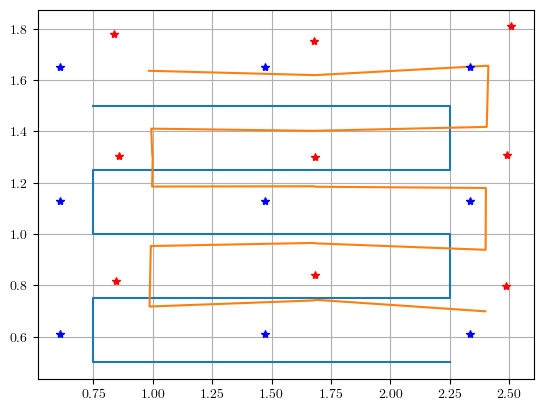

In [66]:
traj = np.load('data/zigzag.npy')
traj_warped = apply_Hs(traj)

print(traj.shape, traj_warped.shape)
plt.plot(traj[:, 0], traj[:, 1], label='original')
plt.plot(traj_warped[:, 0], traj_warped[:, 1], label='warped')
plt.plot(XY9[:, 0], XY9[:, 1], 'b*', label='grid points (commanded)')
plt.plot(xy9[:, 0], xy9[:, 1], 'r*', label='grid points (measured)')

In [67]:
# Export as gcode
def export(fname, xys):
    with open(fname, 'w') as f:
        xs, ys = xys.T * 1e3
        # Write path to file
        f.write(f'G0 X{xs[0]:.3f} Y{ys[0]:.3f}\n')
        for x, y in zip(xs, ys):
            f.write(f'G1 X{x:.3f} Y{y:.3f}\n')
        f.write(f'G0 X{xs[-1]:.3f} Y{ys[-1]:.3f}\n')

export('data/zigzag_multigrid.nc', traj_warped)
np.save('data/zigzag_multigrid.npy', traj_warped)